# Temperature Rule vs Multi-Sensor Random Forest
## Hydraulic Cooler Condition Detection

### 1. Executive Summary

**Decision question:** Does the tested multi-sensor approach improve cooler
condition detection enough to justify additional data-processing and model-maintenance effort?

Across the same 1,604 grouped validation predictions per method, the temperature
baseline misses **9 near-failure cycles** and produces **15 false alerts**.
The multi-sensor forest misses **11 near-failure cycles** and produces **80 false alerts**.
Neither method misses reduced-efficiency cycles.

**Recommendation:** retain the simple method as the baseline for further investigation.
Under the tested feature preparation, model settings, and threshold calibration,
the forest does not justify its added complexity. This does not isolate the value
of extra sensors: both sensor inputs and the modeling method change.

Errors are concentrated in particular validation folds and thresholds vary.
Neither method is validated for deployment. Results are exploratory; no downtime
reduction, avoided breakdowns, or financial savings have been demonstrated.

## 2. Dataset, Target, and Scope

The [UCI hydraulic condition-monitoring dataset](https://archive.ics.uci.edu/dataset/447/condition+monitoring+of+hydraulic+systems)
contains 2,205 measured, 60-second cycles from a ZeMA hydraulic test rig.
A cycle is an observation, not a separate machine or breakdown. Matching rows
across sensor files and profile.txt refer to the same cycle.

The target is recorded cooler condition: **100 = full efficiency**,
**20 = reduced efficiency**, and **3 = close to total failure**.
The two poorer conditions form the degraded class, but misses are reported
separately by severity. This is current-condition detection, not future failure prediction.

Inputs are measurements from 14 sensors: six pressure, four temperature, two flow,
one motor-power, and one vibration sensor. The baseline uses only TS1 mean temperature.
Calculated CE, CP, and SE indicators are excluded pending review of their formulas.
Condition labels, stability, IDs, and split assignments are never predictor inputs.

Reference: Helwig, Pignanelli and Schütze (2015),
*Condition Monitoring of a Complex Hydraulic System Using Multivariate Statistics*,
[DOI: 10.1109/I2MTC.2015.7151267](https://doi.org/10.1109/I2MTC.2015.7151267).

## 3. Data Preparation and Exploratory Finding

Each sensor is summarized by mean and population standard deviation per cycle,
producing 28 features. This handles different sampling rates but discards
within-cycle ordering. Checks cover file dimensions, finite values, alignment,
reference labels, and consistency with the original TS1 average.

The retained exploratory chart compares stable and potentially unstable cycles.
The stability flag is used to interpret results, not as a prediction input.

In [1]:
from zipfile import ZipFile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

filename = "condition+monitoring+of+hydraulic+systems.zip"

# Load matching sensor and reference-condition rows.
with ZipFile(filename) as dataset:
    with dataset.open("TS1.txt") as file:
        temperature = pd.read_csv(file, sep="\t", header=None)
    with dataset.open("profile.txt") as file:
        conditions = pd.read_csv(file, sep="\t", header=None)

conditions.columns = [
    "cooler_condition", "valve_condition", "pump_leakage",
    "accumulator_pressure", "unstable_flag"
]
assert temperature.shape == (2205, 60)
assert conditions.shape == (2205, 5)
assert temperature.index.equals(conditions.index)
assert np.isfinite(temperature.to_numpy()).all()
assert np.isfinite(conditions.to_numpy()).all()
assert conditions["cooler_condition"].isin([3, 20, 100]).all()
assert conditions["unstable_flag"].isin([0, 1]).all()

average_temperature = temperature.mean(axis=1)
cycles = conditions.copy()
cycles["average_temperature_c"] = average_temperature
cycles["is_degraded"] = cycles["cooler_condition"] != 100
print("Validated 2,205 aligned cycles; no missing or non-finite values.")

Validated 2,205 aligned cycles; no missing or non-finite values.


In [2]:
sensor_rates = {
    "PS1": 100, "PS2": 100, "PS3": 100,
    "PS4": 100, "PS5": 100, "PS6": 100,
    "TS1": 1, "TS2": 1, "TS3": 1, "TS4": 1,
    "FS1": 10, "FS2": 10, "EPS1": 100, "VS1": 1
}

sensor_features = pd.DataFrame(index=cycles.index)

with ZipFile(filename) as dataset:
    for sensor, rate in sensor_rates.items():
        with dataset.open(sensor + ".txt") as file:
            readings = pd.read_csv(file, sep="\t", header=None)

        assert readings.shape == (len(cycles), 60 * rate), sensor
        assert np.isfinite(readings.to_numpy()).all(), sensor

        sensor_features[sensor + "_mean"] = readings.mean(axis=1)
        sensor_features[sensor + "_std"] = readings.std(axis=1, ddof=0)

assert np.allclose(sensor_features["TS1_mean"], cycles["average_temperature_c"])
assert sensor_features.index.equals(cycles.index)
feature_columns = sensor_features.columns.tolist()
print("Final feature table:", sensor_features.shape)

Final feature table: (2205, 28)


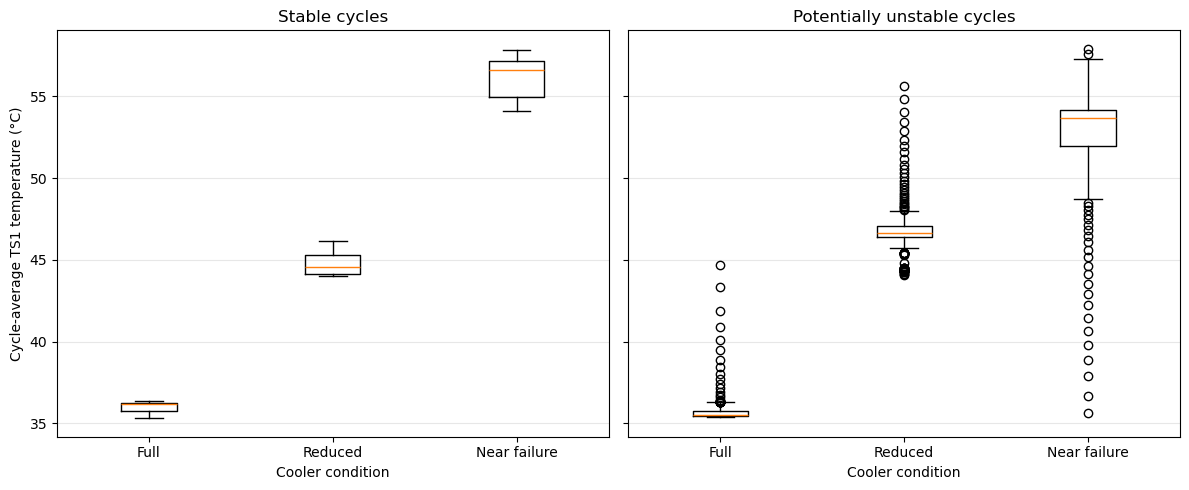

In [3]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, flag, title in [
    (axes[0], 0, "Stable cycles"),
    (axes[1], 1, "Potentially unstable cycles")
]:
    subset = cycles[cycles["unstable_flag"] == flag]

    temperature_groups = [
        subset.loc[
            subset["cooler_condition"] == condition,
            "average_temperature_c"
        ]
        for condition in [100, 20, 3]
    ]

    ax.boxplot(temperature_groups)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(["Full", "Reduced", "Near failure"])
    ax.set_title(title)
    ax.set_xlabel("Cooler condition")
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Cycle-average TS1 temperature (°C)")

plt.tight_layout()
plt.show()

**Finding:** stable cycles have clearly separated temperature ranges, while
potentially unstable cycles overlap. Some near-failure cycles have low temperatures;
some healthy cycles have elevated temperatures. All cycles are retained.
This motivates a simple baseline and a check of whether other sensors help.

## 4. Comparison Method

The original split is preserved: 1,604 development cycles (108 condition groups)
and 601 reserved cycles (36 groups). Main results use five grouped validation
rounds within development data. The reserved set has already been inspected and
does not provide a new independent test; its earlier threshold exercise is in Appendix A.

Groups are exact combinations of cooler, valve, pump, and accumulator conditions.
Matching groups stay together, but grouping does not establish independence or
remove all temporal dependence. Folds are stratified by condition-group counts;
cycle counts can differ substantially.

Within every round, separate groups are used for:
1. **Fitting:** train the forest on sensor summaries.
2. **Calibration:** choose both methods' alert thresholds.
3. **Validation:** assess cycles excluded from both prior steps.

The forest is not refitted after calibration. Its fixed settings are 200 trees,
maximum depth 8, and minimum leaf size 3. No model or sensor search is performed.

**Example selection rule:** at least 99% calibration detection, then maximum
balanced accuracy. Ties favor fewer near-failure misses, fewer total misses,
then the lower threshold. This balances category performance, not operational costs.
The 99% target is an assumption and is not guaranteed in validation.

Baseline candidates are 35–58°C in 0.5°C steps. Forest candidates are score
thresholds 0–1 in 0.01 steps. These scores are not validated failure probabilities.
The baseline is recalibrated per round, rather than fixed at the earlier 42°C.

The full dataset was explored before splitting, and the selection criterion was
revised after earlier evaluation review. The complete comparison is exploratory.

In [4]:
condition_columns = [
    "cooler_condition", "valve_condition", "pump_leakage", "accumulator_pressure"
]
cycles["condition_group"] = cycles.groupby(condition_columns, sort=False).ngroup() + 1
groups = cycles[["condition_group", "cooler_condition"]].drop_duplicates()
assert len(groups) == 144

# Preserve the original split; do not select a new favorable sample.
evaluation_groups = groups.groupby("cooler_condition").sample(n=12, random_state=42)
is_evaluation = cycles["condition_group"].isin(evaluation_groups["condition_group"])
cycles["dataset_split"] = np.where(is_evaluation, "evaluation", "development")
development = cycles.loc[~is_evaluation].copy()
evaluation = cycles.loc[is_evaluation].copy()
assert set(development["condition_group"]).isdisjoint(evaluation["condition_group"])
assert len(development) + len(evaluation) == len(cycles)
assert len(development) == 1604 and len(evaluation) == 601

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split

def policy_metrics(frame, scores, threshold):
    actual = frame["is_degraded"].to_numpy(dtype=bool)
    alert = np.asarray(scores) >= threshold
    condition = frame["cooler_condition"].to_numpy()
    tp = int((actual & alert).sum())
    fn = int((actual & ~alert).sum())
    fp = int((~actual & alert).sum())
    tn = int((~actual & ~alert).sum())
    detection = 100 * tp / (tp + fn)
    false_rate = 100 * fp / (fp + tn)
    return {
        "cycles": len(frame), "detected": tp, "missed": fn,
        "unnecessary_alerts": fp, "correctly_clear": tn,
        "missed_near_failure": int(((condition == 3) & ~alert).sum()),
        "missed_reduced_efficiency": int(((condition == 20) & ~alert).sum()),
        "detection_rate_pct": detection, "false_alert_rate_pct": false_rate,
        "accuracy_pct": 100 * (tp + tn) / len(frame),
        "balanced_accuracy_pct": (detection + 100 - false_rate) / 2,
        "flagged_cycle_rate_pct": 100 * alert.mean()
    }

In [6]:
def choose_threshold(frame, scores, thresholds):
    choices = []
    for threshold in thresholds:
        row = policy_metrics(frame, scores, threshold)
        row["threshold"] = float(threshold)
        choices.append(row)
    choices = pd.DataFrame(choices)
    eligible = choices[choices["detection_rate_pct"] >= 99]
    if eligible.empty:
        raise ValueError("No candidate meets the calibration requirement.")
    best = eligible.sort_values(
        ["balanced_accuracy_pct", "missed_near_failure", "missed", "threshold"],
        ascending=[False, True, True, True]
    ).iloc[0]
    return float(best["threshold"])

In [7]:
development_group_table = development[
    ["condition_group", "cooler_condition"]
].drop_duplicates().reset_index(drop=True)

outer_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_results = []
prediction_tables = []

for fold, (remaining_positions, validation_positions) in enumerate(
    outer_splitter.split(development_group_table,
                         development_group_table["cooler_condition"]), start=1
):
    remaining_groups = development_group_table.iloc[remaining_positions]
    validation_groups = development_group_table.iloc[validation_positions]
    fitting_groups, calibration_groups = train_test_split(
        remaining_groups, test_size=0.25, random_state=100 + fold,
        stratify=remaining_groups["cooler_condition"]
    )

    def take_groups(group_table):
        return development[development["condition_group"].isin(
            group_table["condition_group"]
        )].copy()

    fitting = take_groups(fitting_groups)
    calibration = take_groups(calibration_groups)
    validation_fold = take_groups(validation_groups)
    fit_ids = set(fitting["condition_group"])
    cal_ids = set(calibration["condition_group"])
    val_ids = set(validation_fold["condition_group"])
    assert fit_ids.isdisjoint(cal_ids)
    assert fit_ids.isdisjoint(val_ids) and cal_ids.isdisjoint(val_ids)
    for frame in [fitting, calibration, validation_fold]:
        assert set(frame["cooler_condition"]) == {3, 20, 100}

    forest = RandomForestClassifier(
        n_estimators=200, max_depth=8, min_samples_leaf=3,
        random_state=42, n_jobs=-1
    )
    forest.fit(sensor_features.loc[fitting.index, feature_columns],
               fitting["is_degraded"])
    positive_column = list(forest.classes_).index(True)
    forest_calibration = forest.predict_proba(
        sensor_features.loc[calibration.index, feature_columns]
    )[:, positive_column]
    forest_validation = forest.predict_proba(
        sensor_features.loc[validation_fold.index, feature_columns]
    )[:, positive_column]

    baseline_threshold = choose_threshold(
        calibration, calibration["average_temperature_c"],
        np.arange(35, 58.01, 0.5)
    )
    forest_threshold = choose_threshold(
        calibration, forest_calibration, np.linspace(0, 1, 101)
    )

    for model, scores, threshold in [
        ("Temperature baseline", validation_fold["average_temperature_c"], baseline_threshold),
        ("Multi-sensor forest", forest_validation, forest_threshold)
    ]:
        row = policy_metrics(validation_fold, scores, threshold)
        row.update({"fold": fold, "model": model,
                    "threshold": threshold, "calibration_cycles": len(calibration),
                    "fitting_cycles": len(fitting)})
        fold_results.append(row)

        predictions = validation_fold[
            ["cooler_condition", "unstable_flag", "is_degraded", "condition_group"]
        ].copy()
        predictions.insert(0, "cycle_id", validation_fold.index + 1)
        predictions["fold"] = fold
        predictions["model"] = model
        predictions["score"] = np.asarray(scores)
        predictions["threshold"] = threshold
        predictions["inspection_alert"] = np.asarray(scores) >= threshold
        prediction_tables.append(predictions)



cv_results = pd.DataFrame(fold_results)
cv_predictions = pd.concat(prediction_tables, ignore_index=True)
assert not cv_predictions.duplicated(["model", "cycle_id"]).any()
assert cv_predictions.groupby("model").size().eq(len(development)).all()
print("Five grouped rounds completed; each method has 1,604 validation predictions.")

Five grouped rounds completed; each method has 1,604 validation predictions.


## 5. Results and Difficult-Condition Diagnostics

Each method produces one excluded-group prediction per development cycle.
Pooled rates are computed from combined counts, not averages of fold rates.
The paired observations support a descriptive comparison, not a formal
significance or new-equipment generalization claim.

,model,cycles,missed_near_failure,missed_reduced_efficiency,unnecessary_alerts,detection_rate_pct,false_alert_rate_pct
0,Temperature baseline,1604,9,0,15,99.09,2.43
1,Multi-sensor forest,1604,11,0,80,98.88,12.94


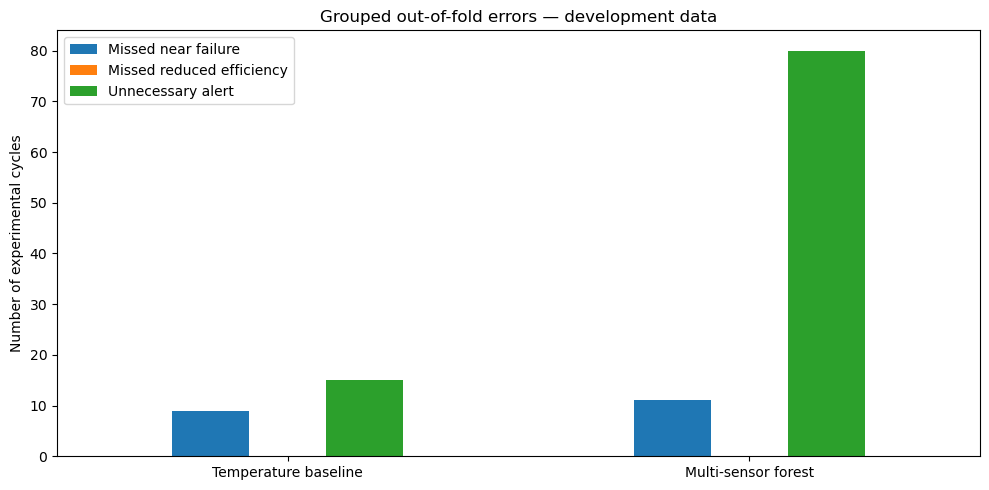

In [8]:
pooled_rows = []
subgroup_rows = []
for model, predictions in cv_predictions.groupby("model", sort=False):
    # Boolean decisions can be evaluated with threshold 0.5.
    row = policy_metrics(predictions, predictions["inspection_alert"], 0.5)
    row["model"] = model
    pooled_rows.append(row)
    for (condition, unstable), subset in predictions.groupby(
        ["cooler_condition", "unstable_flag"]
    ):
        degraded = condition != 100
        error_count = int((~subset["inspection_alert"]).sum()) if degraded else int(
            subset["inspection_alert"].sum()
        )
        subgroup_rows.append({
            "model": model, "cooler_condition": condition,
            "unstable_flag": unstable, "cycles": len(subset),
            "error_type": "Missed degradation" if degraded else "Unnecessary alert",
            "errors": error_count, "error_rate_pct": 100 * error_count / len(subset)
        })

model_comparison = pd.DataFrame(pooled_rows)
subgroup_comparison = pd.DataFrame(subgroup_rows)
display(model_comparison[[
    "model", "cycles", "missed_near_failure", "missed_reduced_efficiency",
    "unnecessary_alerts", "detection_rate_pct", "false_alert_rate_pct"
]].round(2))

# A simple paired visual: error counts, not a single headline accuracy score.
model_comparison.set_index("model")[[
    "missed_near_failure", "missed_reduced_efficiency", "unnecessary_alerts"
]].plot.bar(figsize=(10, 5), rot=0)
plt.title("Grouped out-of-fold errors — development data")
plt.ylabel("Number of experimental cycles")
plt.xlabel("")
plt.legend(["Missed near failure", "Missed reduced efficiency", "Unnecessary alert"])
plt.tight_layout()
plt.show()

**Finding:** the forest misses two more near-failure cycles and generates
65 more healthy false alerts. This comparison concerns the complete model-and-threshold
procedure, not the intrinsic usefulness of the extra sensors.

### Error Concentration and Calibration Sensitivity

Rates below use the relevant condition count as denominator. Counts remain in
the table so large experimental groups do not hide behind percentages. Baseline
thresholds are in °C; forest thresholds are unitless scores and cannot be compared
numerically across methods.

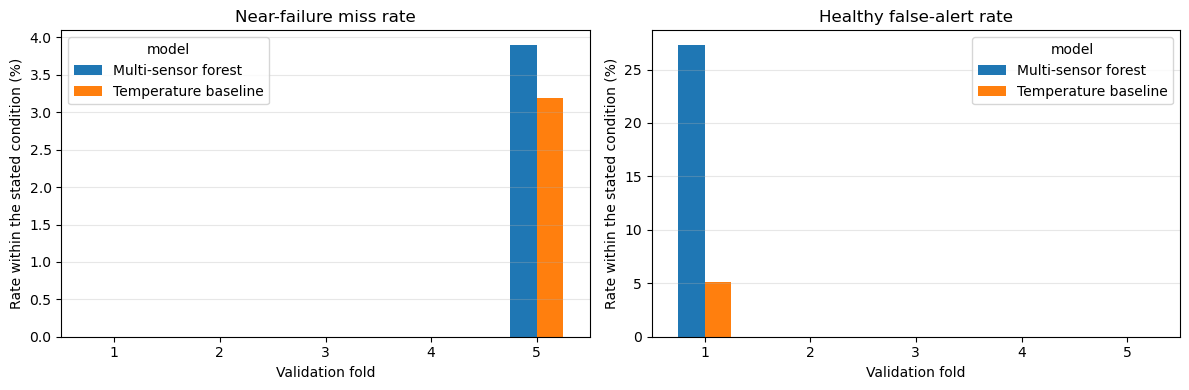

,fold,model,threshold,near_failure_cycles,missed_near_failure,near_failure_miss_rate_pct,healthy_cycles,unnecessary_alerts,healthy_false_alert_rate_pct
0,1,Temperature baseline,36.50,81,0,0.00,293,15,5.12
1,1,Multi-sensor forest,0.06,81,0,0.00,293,80,27.30
2,2,Temperature baseline,43.50,82,0,0.00,103,0,0.00
3,2,Multi-sensor forest,0.81,82,0,0.00,103,0,0.00
4,3,Temperature baseline,36.50,71,0,0.00,82,0,0.00
5,3,Multi-sensor forest,0.08,71,0,0.00,82,0,0.00
6,4,Temperature baseline,36.50,72,0,0.00,70,0,0.00
7,4,Multi-sensor forest,0.16,72,0,0.00,70,0,0.00
8,5,Temperature baseline,43.50,282,9,3.19,70,0,0.00
9,5,Multi-sensor forest,0.89,282,11,3.90,70,0,0.00


In [9]:
# Calculate subgroup denominators once, using one prediction per cycle.
baseline_predictions = cv_predictions[
    cv_predictions["model"] == "Temperature baseline"
]
fold_conditions = pd.crosstab(
    baseline_predictions["fold"], baseline_predictions["cooler_condition"]
).rename(columns={3: "near_failure_cycles", 20: "reduced_cycles", 100: "healthy_cycles"})

fold_diagnostics = cv_results.merge(
    fold_conditions, left_on="fold", right_index=True, validate="many_to_one"
)
fold_diagnostics["near_failure_miss_rate_pct"] = (
    100 * fold_diagnostics["missed_near_failure"] / fold_diagnostics["near_failure_cycles"]
)
fold_diagnostics["healthy_false_alert_rate_pct"] = (
    100 * fold_diagnostics["unnecessary_alerts"] / fold_diagnostics["healthy_cycles"]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column, title in [
    (axes[0], "near_failure_miss_rate_pct", "Near-failure miss rate"),
    (axes[1], "healthy_false_alert_rate_pct", "Healthy false-alert rate")
]:
    chart = fold_diagnostics.pivot(index="fold", columns="model", values=column)
    chart.plot.bar(ax=ax, rot=0)
    ax.set_title(title)
    ax.set_xlabel("Validation fold")
    ax.set_ylabel("Rate within the stated condition (%)")
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(fold_diagnostics[[
    "fold", "model", "threshold", "near_failure_cycles", "missed_near_failure",
    "near_failure_miss_rate_pct", "healthy_cycles", "unnecessary_alerts",
    "healthy_false_alert_rate_pct"
]].round(2))

All false alerts occur in fold 1: **15/293 healthy cycles (5.12%)** for the
baseline versus **80/293 (27.30%)** for the forest. All near-failure misses occur
in fold 5: **9/282 (3.19%)** versus **11/282 (3.90%)**. Folds 2–4 have no errors.

Fold sizes contribute to error concentration but do not explain it alone.
Baseline thresholds range from 36.5°C to 43.5°C; forest thresholds range from
0.06 to 0.89. The variation is consistent with sensitivity to calibration coverage,
but the cause has not been established. Inspecting the underlying fitting,
calibration, and validation conditions is needed before changing the method.

## 6. Recommendation and Limits

**Retain the temperature method as the comparison baseline; do not recommend a
universal threshold or deployment.** The tested forest offers no error reduction
to offset added preparation, integration, versioning, and monitoring requirements.
If the sensors already exist, additional sensor purchase costs should not be assumed.

The practical contribution is a reproducible method for comparing monitoring
options before a pilot. Severe misses and false alerts matter, but cycle errors
are not independent breakdowns, inspection visits, or direct measures of workload.
No validated financial, downtime, or safety benefit is established.

### Evidence Needed Before a Pilot

- Obtain independent equipment data covering warm-up, transitions, and changing loads.
- Investigate the conditions producing errors in folds 1 and 5.
- Agree acceptable consequences by severity and available review capacity with engineers.
- Establish how repeated alerts become review tasks, then measure detection delay
  and review effort rather than treating every flagged cycle as a visit.

Key limitations are one test rig, repeated observations, prior full-data exploration,
revised selection criteria, unequal group sizes, and calibration sensitivity.
These results do not prove that all multi-sensor models are worse. Further model
complexity should follow diagnosis and better validation coverage, not precede them.

### Dashboard Data

The following technical export step saves five tables. Use paired validation
predictions for dashboard performance metrics; keep earlier single-split
results separate. There are two prediction rows per cycle, one per method.

In [10]:
from pathlib import Path

output_dir = Path("data") / "processed" / "model_comparison"
output_dir.mkdir(parents=True, exist_ok=True)

cv_predictions["alert_outcome"] = np.select(
    [cv_predictions["is_degraded"] & cv_predictions["inspection_alert"],
     cv_predictions["is_degraded"] & ~cv_predictions["inspection_alert"],
     ~cv_predictions["is_degraded"] & cv_predictions["inspection_alert"]],
    ["Detected degradation", "Missed degradation", "Unnecessary alert"],
    default="Correctly clear"
)

cv_predictions.to_csv(output_dir / "cv_cycle_predictions.csv", index=False)
cv_results.to_csv(output_dir / "cv_fold_results.csv", index=False)
model_comparison.to_csv(output_dir / "model_comparison.csv", index=False)
subgroup_comparison.to_csv(output_dir / "subgroup_comparison.csv", index=False)

fold_diagnostics.to_csv(output_dir / "fold_diagnostics.csv", index=False)
print("Saved five Power BI tables to:", output_dir.resolve())

Saved five Power BI tables to: C:\Users\diept\Portfolio----\data\processed\model_comparison


# Appendix A. Earlier Single-Split Temperature Exercise

This appendix preserves the earlier learning analysis and threshold trade-offs.
It is not the main evidence for the model comparison. The 42°C candidate and its
zero-error, 601-cycle follow-up must not be substituted for the per-round baseline
used in Section 5. The reserved set was inspected and the criterion revised afterward.

### A.1 Comparing Temperature Thresholds

I test thresholds from 35°C to 58°C in 0.5°C steps,
using development data only.

For each threshold, I calculate detection rate, false alert rate,
and flagged-cycle rate.

This lets me examine the trade-off before selecting a policy.

In [11]:
results = []

actual = development["is_degraded"]
temperature_values = development["average_temperature_c"]

for threshold in [35 + 0.5 * step for step in range(47)]:

    alert = temperature_values >= threshold

    detected = (actual & alert).sum()
    missed = (actual & ~alert).sum()
    unnecessary = (~actual & alert).sum()

    results.append({
        "threshold_c": threshold,
        "detected": detected,
        "missed": missed,
        "unnecessary_alerts": unnecessary,
        "detection_rate_pct": 100 * detected / actual.sum(),
        "false_alert_rate_pct": 100 * unnecessary / (~actual).sum(),
        "flagged_cycle_rate_pct": 100 * alert.mean()
    })

threshold_results = pd.DataFrame(results)

# Show every fourth row: thresholds spaced 2°C apart
threshold_results.iloc[::4].round(2)

,threshold_c,detected,missed,unnecessary_alerts,detection_rate_pct,false_alert_rate_pct,flagged_cycle_rate_pct
0,35.0,986,0,618,100.00,100.00,100.00
4,37.0,984,2,12,99.80,1.94,62.09
8,39.0,982,4,6,99.59,0.97,61.60
12,41.0,980,6,3,99.39,0.49,61.28
16,43.0,977,9,2,99.09,0.32,61.03
20,45.0,704,282,0,71.40,0.00,43.89
24,47.0,571,415,0,57.91,0.00,35.60
28,49.0,563,423,0,57.10,0.00,35.10
32,51.0,546,440,0,55.38,0.00,34.04
36,53.0,497,489,0,50.41,0.00,30.99


#### Interpretation

Increasing the temperature threshold reduces both detection
and the percentage of cycles flagged for review.

At 35°C, every cycle is flagged. All degradation is detected,
but all 618 healthy cycles also trigger unnecessary alerts.

At 43°C, the rule detects 99.09% of degraded cycles,
misses 9, and generates 2 unnecessary alerts.

At 45°C, unnecessary alerts fall to zero, but detection drops
to 71.40%, with 282 degraded cycles missed.

This illustrates the trade-off: reducing review workload by raising
the threshold can leave substantially more degradation undetected.

A lower flagged-cycle rate is therefore not automatically better.
I need an explicit detection requirement before selecting a policy.

The displayed table shows every fourth tested threshold.
The complete results include thresholds spaced 0.5°C apart.

### A.2 Visualizing the Threshold Trade-off

I plot detection rate and false alert rate against temperature threshold.

Both rates use the same percentage scale, but different denominators:
degraded cycles for detection rate and healthy cycles for false alert rate.

This chart uses development data only.

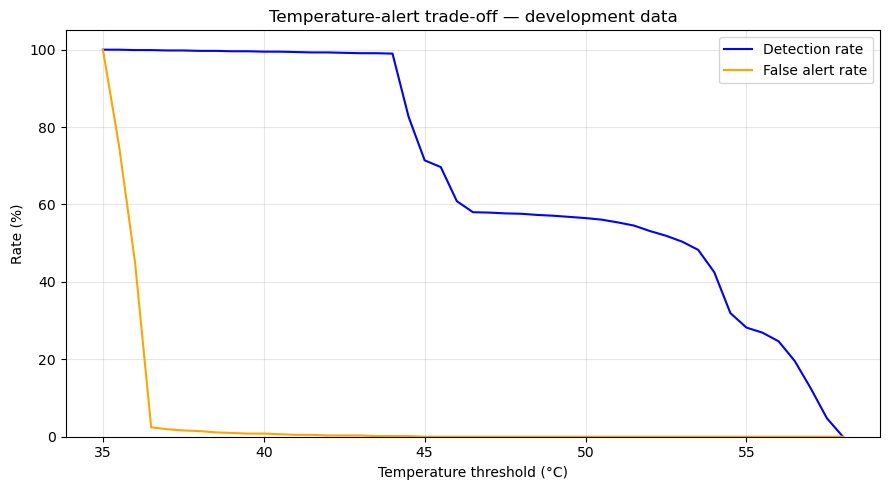

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_results["threshold_c"],
    threshold_results["detection_rate_pct"],
    label="Detection rate",
    color="blue"
)

plt.plot(
    threshold_results["threshold_c"],
    threshold_results["false_alert_rate_pct"],
    label="False alert rate",
    color="orange"
)

plt.xlabel("Temperature threshold (°C)")
plt.ylabel("Rate (%)")
plt.title("Temperature-alert trade-off — development data")

plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

#### Interpretation

Low thresholds detect nearly all degraded cycles but can also flag
healthy cycles. As the threshold increases, false alerts decline.

Detection remains above 99% at 43°C, but falls sharply by 45°C.
Raising the threshold beyond this region reduces workload partly
by failing to flag degraded cycles.

The chart supports choosing a threshold using a stated decision
requirement rather than simply minimizing the number of alerts.

### A.3 Comparing Candidate Policies in an Industrial Context

Missed near-failure conditions and missed reduced-efficiency conditions
are reported separately. They have different operational implications;
I do not invent monetary or safety penalties from this dataset.

I compare development results across candidate thresholds, including
the earlier 43.5°C rule. Accuracy and balanced accuracy are supporting
metrics, not estimates of industrial benefit. Flagged cycles are not
inspection visits, and no downtime or savings are inferred.

In [13]:
# Add summary metrics to the complete threshold table.
threshold_results["accuracy_pct"] = 100 * (
    1 - (threshold_results["missed"]
         + threshold_results["unnecessary_alerts"]) / len(development)
)
threshold_results["specificity_pct"] = (
    100 - threshold_results["false_alert_rate_pct"]
)
threshold_results["balanced_accuracy_pct"] = (
    threshold_results["detection_rate_pct"]
    + threshold_results["specificity_pct"]
) / 2

# Count misses separately for both severity levels at every threshold.
for condition, name in [(3, "near_failure"), (20, "reduced_efficiency")]:
    condition_rows = development["cooler_condition"] == condition
    threshold_results["missed_" + name] = [
        int((condition_rows & (
            development["average_temperature_c"] < threshold
        )).sum())
        for threshold in threshold_results["threshold_c"]
    ]

candidate_thresholds = [39.5, 40.5, 41.0, 42.0, 43.5]
candidate_comparison = threshold_results[
    threshold_results["threshold_c"].isin(candidate_thresholds)
].copy()

comparison_columns = [
    "threshold_c", "missed_near_failure", "missed_reduced_efficiency",
    "unnecessary_alerts", "detection_rate_pct", "false_alert_rate_pct",
    "flagged_cycle_rate_pct", "accuracy_pct", "balanced_accuracy_pct"
]
display(candidate_comparison[comparison_columns].round(2))

,threshold_c,missed_near_failure,missed_reduced_efficiency,unnecessary_alerts,detection_rate_pct,false_alert_rate_pct,flagged_cycle_rate_pct,accuracy_pct,balanced_accuracy_pct
9,39.5,4,0,5,99.59,0.81,61.53,99.44,99.39
11,40.5,5,0,4,99.49,0.65,61.41,99.44,99.42
12,41.0,6,0,3,99.39,0.49,61.28,99.44,99.45
14,42.0,7,0,2,99.29,0.32,61.16,99.44,99.48
17,43.5,9,0,1,99.09,0.16,60.97,99.38,99.46


#### Interpretation

The 42°C candidate misses seven degraded cycles and generates two
unnecessary alerts; 43.5°C misses nine and generates one unnecessary alert.
Thus the higher threshold avoids one false alert at the expense of two
additional missed degraded cycles. The severity-specific columns above
show which cooler conditions are missed; aggregate accuracy hides this.

Lower candidate thresholds remain credible alternatives when avoiding
missed degradation takes priority. Without operational costs and review
capacity, the evidence does not establish a unique industrial optimum.

### A.4 Provisional Baseline Selection

For this exploratory comparison, retain a minimum 99% development
detection requirement, then maximize balanced accuracy. Ties favor fewer
missed near-failure cycles, fewer total misses, and the lower threshold.

This transparent example criterion balances healthy and degraded category
performance, not business consequences. The severity table remains part
of the decision. The criterion was revised after the earlier evaluation
was inspected; subsequent results are exploratory, not a new untouched test.

In [14]:
eligible = threshold_results[
    threshold_results["detection_rate_pct"] >= 99
].copy()
if eligible.empty:
    raise ValueError("No threshold meets the assumed detection requirement.")

ranked = eligible.sort_values(
    ["balanced_accuracy_pct", "missed_near_failure", "missed", "threshold_c"],
    ascending=[False, True, True, True]
)
selected_policy = ranked.iloc[0]
selected_threshold = float(selected_policy["threshold_c"])
print("Provisional baseline threshold:", selected_threshold, "°C")
display(ranked[comparison_columns].head().round(2))

Provisional baseline threshold: 42.0 °C


,threshold_c,missed_near_failure,missed_reduced_efficiency,unnecessary_alerts,detection_rate_pct,false_alert_rate_pct,flagged_cycle_rate_pct,accuracy_pct,balanced_accuracy_pct
14,42.0,7,0,2,99.29,0.32,61.16,99.44,99.48
17,43.5,9,0,1,99.09,0.16,60.97,99.38,99.46
12,41.0,6,0,3,99.39,0.49,61.28,99.44,99.45
15,42.5,8,0,2,99.19,0.32,61.10,99.38,99.43
11,40.5,5,0,4,99.49,0.65,61.41,99.44,99.42


#### Interpretation

The selected provisional baseline is 42°C. On development data it detects
979 of 986 degraded cycles (99.29%), misses seven, and flags two of 618
healthy cycles unnecessarily (0.32%). Balanced accuracy is 99.48%.

The advantage in balanced accuracy over 43.5°C is small. This choice is
not a validated operating limit and does not establish that seven missed
observations are acceptable in practice.

### A.5 Inspecting Misses by Severity and Stability

I compare 42°C and 43.5°C within each recorded condition and stability
category. The same experiment can contribute repeated cycles; these are
not separate breakdowns. Stability is used for diagnosis, not as an alert input.

In [15]:
error_tables = []
for threshold in [42.0, 43.5]:
    review = development.copy()
    review["missed_degradation"] = (
        review["is_degraded"]
        & (review["average_temperature_c"] < threshold)
    )
    review["unnecessary_alert"] = (
        ~review["is_degraded"]
        & (review["average_temperature_c"] >= threshold)
    )
    summary = review.groupby(["cooler_condition", "unstable_flag"]).agg(
        cycle_count=("is_degraded", "size"),
        missed_degradation=("missed_degradation", "sum"),
        unnecessary_alerts=("unnecessary_alert", "sum")
    ).reset_index()
    summary.insert(0, "threshold_c", threshold)
    error_tables.append(summary)

error_breakdown = pd.concat(error_tables, ignore_index=True)
display(error_breakdown)

,threshold_c,cooler_condition,unstable_flag,cycle_count,missed_degradation,unnecessary_alerts
0,42.0,3,0,360,0,0
1,42.0,3,1,228,7,0
2,42.0,20,0,360,0,0
3,42.0,20,1,38,0,0
4,42.0,100,0,369,0,0
5,42.0,100,1,249,0,2
6,43.5,3,0,360,0,0
7,43.5,3,1,228,9,0
8,43.5,20,0,360,0,0
9,43.5,20,1,38,0,0


#### Interpretation

Use this table to identify the severity and stability categories behind
each error. A missed near-failure observation deserves particular review,
but these counts do not quantify failure probability or actual harm.

I do not infer time to detection or alert episodes from row adjacency:
the file is an experimental sequence, not a documented fleet event log.

### A.6 Exploratory Evaluation of the Provisional Baseline

The 42°C threshold is applied without further tuning to the existing
evaluation groups. These groups have already been inspected, and the
criterion was revised afterward. This is a descriptive follow-up check,
not an independent final performance estimate.

In [16]:
evaluation = evaluation.copy()
evaluation["inspection_alert"] = (
    evaluation["average_temperature_c"] >= selected_threshold
)
actual = evaluation["is_degraded"]
alert = evaluation["inspection_alert"]
detected = int((actual & alert).sum())
missed = int((actual & ~alert).sum())
unnecessary = int((~actual & alert).sum())
correctly_clear = int((~actual & ~alert).sum())
assert detected + missed + unnecessary + correctly_clear == len(evaluation)

evaluation_results = pd.DataFrame([{
    "threshold_c": selected_threshold,
    "total_cycles": len(evaluation),
    "detected": detected, "missed": missed,
    "unnecessary_alerts": unnecessary, "correctly_clear": correctly_clear,
    "detection_rate_pct": 100 * detected / actual.sum(),
    "false_alert_rate_pct": 100 * unnecessary / (~actual).sum(),
    "flagged_cycle_rate_pct": 100 * alert.mean()
}])
display(evaluation_results.round(2))

evaluation_breakdown = evaluation.groupby(
    ["cooler_condition", "unstable_flag"]
).agg(
    cycle_count=("average_temperature_c", "size"),
    alerts=("inspection_alert", "sum"),
    min_temperature=("average_temperature_c", "min"),
    max_temperature=("average_temperature_c", "max")
).reset_index()
display(evaluation_breakdown.round(2))

,threshold_c,total_cycles,detected,missed,unnecessary_alerts,correctly_clear,detection_rate_pct,false_alert_rate_pct,flagged_cycle_rate_pct
0,42.0,601,478,0,0,123,100.0,0.0,79.53


,cooler_condition,unstable_flag,cycle_count,alerts,min_temperature,max_temperature
0,3,0,120,120,54.17,57.57
1,3,1,24,24,54.37,57.90
2,20,0,120,120,44.00,46.01
3,20,1,214,214,44.08,55.62
4,100,0,120,0,35.54,36.37
5,100,1,3,0,35.77,36.35


#### Interpretation

The 42°C baseline detects all 478 degraded evaluation cycles and leaves
all 123 healthy cycles unflagged. It flags 79.53% of evaluation cycles.

The result is facilitated by a temperature gap: healthy evaluation cycles
are at or below 36.37°C and degraded cycles start at 44.00°C. Only three
healthy evaluation cycles are potentially unstable. The zero-error result
therefore does not resolve the difficult overlap seen in development data.